In [4]:
import pandas as pd
import os

df = pd.read_csv("data/raw/HUPA0001P.csv", sep = ";")

df.head()

,time,glucose,calories,heart_rate,steps,basal_rate,bolus_volume_delivered,carb_input
0,2018-06-13T18:40:00,332.0,6.3595,82.322835,34.0,0.091667,0.0,0.0
1,2018-06-13T18:45:00,326.0,7.7280,83.740157,0.0,0.091667,0.0,0.0
2,2018-06-13T18:50:00,330.0,4.7495,80.525180,0.0,0.091667,0.0,0.0
3,2018-06-13T18:55:00,324.0,6.3595,89.129032,20.0,0.091667,0.0,0.0
4,2018-06-13T19:00:00,306.0,5.1520,92.495652,0.0,0.075000,0.0,0.0


In [ ]:
df.shape

(4096, 8)

In [5]:
df.dtypes

time                          str
glucose                   float64
calories                  float64
heart_rate                float64
steps                     float64
basal_rate                float64
bolus_volume_delivered    float64
carb_input                float64
dtype: object

In [ ]:
df.columns

Index(['time', 'glucose', 'calories', 'heart_rate', 'steps', 'basal_rate',
       'bolus_volume_delivered', 'carb_input'],
      dtype='str')

In [ ]:
df.isna().sum()

time                      0
glucose                   0
calories                  0
heart_rate                0
steps                     0
basal_rate                0
bolus_volume_delivered    0
carb_input                0
dtype: int64

In [ ]:
df.describe()

,glucose,calories,heart_rate,steps,basal_rate,bolus_volume_delivered,carb_input
count,4096.000000,4096.000000,4096.000000,4096.000000,4096.000000,4096.000000,4096.000000
mean,181.443726,5.920327,80.827004,19.467529,0.049675,0.038477,0.029541
std,70.644633,3.460342,12.929865,57.332804,0.022216,0.344373,0.310549
min,40.000000,4.025000,53.462278,0.000000,0.000000,0.000000,0.000000
25%,131.000000,4.025000,69.755759,0.000000,0.037500,0.000000,0.000000
50%,165.666667,4.186000,81.007930,0.000000,0.041667,0.000000,0.000000
75%,222.000000,6.440000,89.834402,8.000000,0.070833,0.000000,0.000000
max,444.000000,37.513000,167.322581,621.000000,0.091667,5.200000,4.000000


In [ ]:
df["time"] = pd.to_datetime(df["time"], errors="coerce")

print("Start time:", df["time"].min())
print("End time:", df["time"].max())
print("Invalid time:", df["time"].isna().sum())
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate timestamps:", df["time"].duplicated().sum())

Start time: 2018-06-13 18:40:00
End time: 2018-06-27 23:55:00
Invalid time: <bound method Series.sum of 0       False
1       False
2       False
3       False
4       False
        ...  
4091    False
4092    False
4093    False
4094    False
4095    False
Name: time, Length: 4096, dtype: bool>
Duplicate rows: 0
Duplicate timestamps: 0


In [7]:
missing_values = df.isna().sum()

print("Missing values by column:")
print(missing_values)

print("\nTotal missing values:", missing_values.sum())

print("\nMissing values percentage:")
print((df.isna().mean() * 100).round(2))

Missing values by column:
time                      0
glucose                   0
calories                  0
heart_rate                0
steps                     0
basal_rate                0
bolus_volume_delivered    0
carb_input                0
dtype: int64

Total missing values: 0

Missing values percentage:
time                      0.0
glucose                   0.0
calories                  0.0
heart_rate                0.0
steps                     0.0
basal_rate                0.0
bolus_volume_delivered    0.0
carb_input                0.0
dtype: float64


In [13]:
print("Unique values by column:")

for column in df.columns:
    print(f"{column}: {df[column].nunique()} unique values")

Unique values by column:
time: 4096 unique values
glucose: 577 unique values
calories: 654 unique values
heart_rate: 4015 unique values
steps: 243 unique values
basal_rate: 13 unique values
bolus_volume_delivered: 23 unique values
carb_input: 8 unique values


In [14]:
print("Glucose minimum", df["glucose"].min())
print("Glucose maximum", df["glucose"].max())
print("Glucose mean", round(df["glucose"].mean(), 2))
print("Glucose median", round(df["glucose"].median(), 2))

print("Glucose percentiles:")
print(df["glucose"].quantile([0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]))

Glucose minimum 40.0
Glucose maximum 444.0
Glucose mean 181.44
Glucose median 165.67
Glucose percentiles:
0.01     64.950000
0.05     87.000000
0.25    131.000000
0.50    165.666667
0.75    222.000000
0.95    326.000000
0.99    396.050000
Name: glucose, dtype: float64


In [15]:
numeric_columns = df.select_dtypes(include="number").columns
negative_values = (df[numeric_columns] < 0).sum()

print("Negative values by column:")
print(negative_values)

Negative values by column:
glucose                   0
calories                  0
heart_rate                0
steps                     0
basal_rate                0
bolus_volume_delivered    0
carb_input                0
dtype: int64


In [17]:
valid_times = df["time"].dropna()

print("Timestamps are sorted:", valid_times.is_monotonic_increasing)
print("Earliest timestamp:", valid_times.min())
print("Latest timestamp:", valid_times.max())

Timestamps are sorted: True
Earliest timestamp: 2018-06-13 18:40:00
Latest timestamp: 2018-06-27 23:55:00


In [18]:
time_differences = df["time"].sort_values().diff()

print("Most common time intervals:")
print(time_differences.value_counts().head(10))

print("\nMedian time interval:")
print(time_differences.median())

Most common time intervals:
time
0 days 00:05:00    4095
Name: count, dtype: int64

Median time interval:
0 days 00:05:00


In [4]:
import os
print("Current working directory:")
print(os.getcwd())

print("\nFiles and folders here:")
print(os.listdir())

Current working directory:
c:\Users\Lenovo\Documents\GitHub\diabetes-cgm-analysis\notebooks

Files and folders here:
['01_data_exploration.ipynb']


In [6]:
import os

summary_path = "../data/processed/validation_summary.csv"

print("File exists:", os.path.exists(summary_path))

File exists: True


In [7]:
import pandas as pd

summary = pd.read_csv("../data/processed/validation_summary.csv")

print("Number of files:", len(summary))
print("\nValidation summary:")
print(summary.to_string(index=False))

print("\nTime interval differences:")
print(summary[["file", "min_interval", "max_interval"]].to_string(index=False))

Number of files: 25

Validation summary:
         file   rows  columns  missing_values  duplicate_rows  duplicate_timestamps  invalid_timestamps    min_interval    max_interval
HUPA0001P.csv   4096        8               0               0                     0                   0 0 days 00:05:00 0 days 00:05:00
HUPA0002P.csv   3181        8               0               0                     0                   0 0 days 00:05:00 0 days 00:05:00
HUPA0003P.csv   3770        8               0               0                     0                   0 0 days 00:05:00 0 days 00:05:00
HUPA0004P.csv   3184        8               0               0                     0                   0 0 days 00:05:00 0 days 00:05:00
HUPA0005P.csv   3858        8               0               0                     0                   0 0 days 00:05:00 0 days 00:05:00
HUPA0006P.csv   2290        8               0               0                     0                   0 0 days 00:05:00 0 days 00:05:00
HUPA000

In [8]:
import pandas as pd

summary = pd.read_csv("../data/processed/validation_summary.csv")

print("Number of files:", len(summary))
print("Total rows:", summary["rows"].sum())
print("Total missing values:", summary["missing_values"].sum())
print("Total duplicate rows:", summary["duplicate_rows"].sum())
print("Total invalid timestamps:", summary["invalid_timestamps"].sum())

print("\nFiles with missing values:")
print(summary[summary["missing_values"] > 0][["file", "missing_values"]])

print("\nFiles with duplicate rows:")
print(summary[summary["duplicate_rows"] > 0][["file", "duplicate_rows"]])

Number of files: 25
Total rows: 309392
Total missing values: 0
Total duplicate rows: 0
Total invalid timestamps: 0

Files with missing values:
Empty DataFrame
Columns: [file, missing_values]
Index: []

Files with duplicate rows:
Empty DataFrame
Columns: [file, duplicate_rows]
Index: []


In [9]:
import pandas as pd
import matplotlib.pyplot as plt

file_path = "../data/raw/HUPA0001P.csv"

df = pd.read_csv(file_path, sep=";")

df["time"] = pd.to_datetime(df["time"], errors="coerce")

print("Number of records:", len(df))
print("Start time:", df["time"].min())
print("End time:", df["time"].max())
print("Mean glucose:", df["glucose"].mean())
print("Minimum glucose:", df["glucose"].min())
print("Maximum glucose:", df["glucose"].max())

Number of records: 4096
Start time: 2018-06-13 18:40:00
End time: 2018-06-27 23:55:00
Mean glucose: 181.4437255859375
Minimum glucose: 40.0
Maximum glucose: 444.0


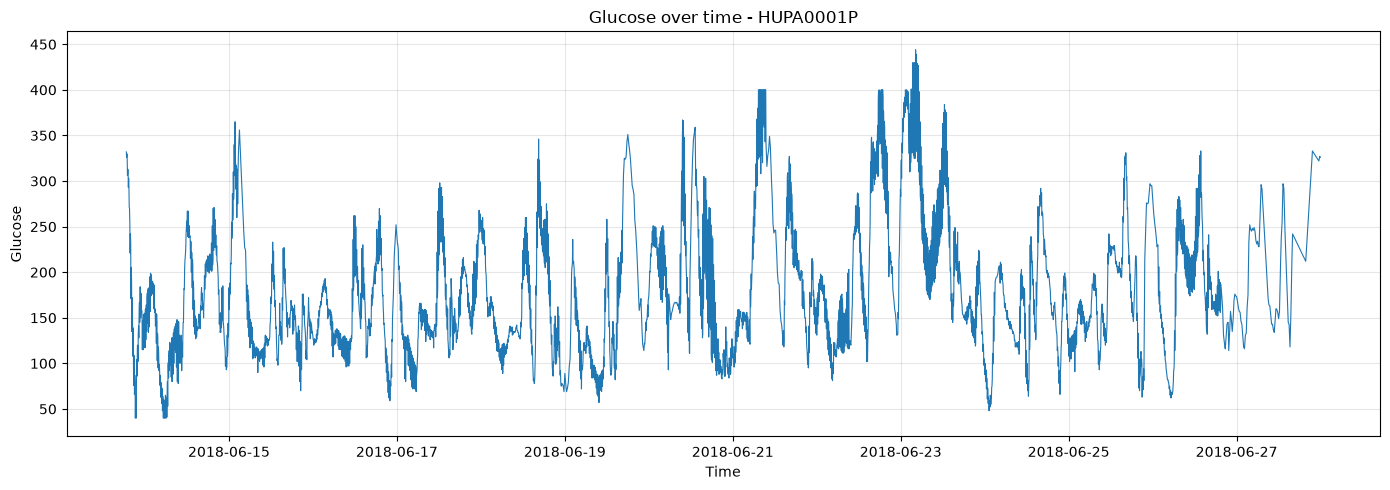

In [10]:
plt.figure(figsize=(14, 5))

plt.plot(df["time"], df["glucose"], linewidth=0.8)

plt.title("Glucose over time - HUPA0001P")
plt.xlabel("Time")
plt.ylabel("Glucose")
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()

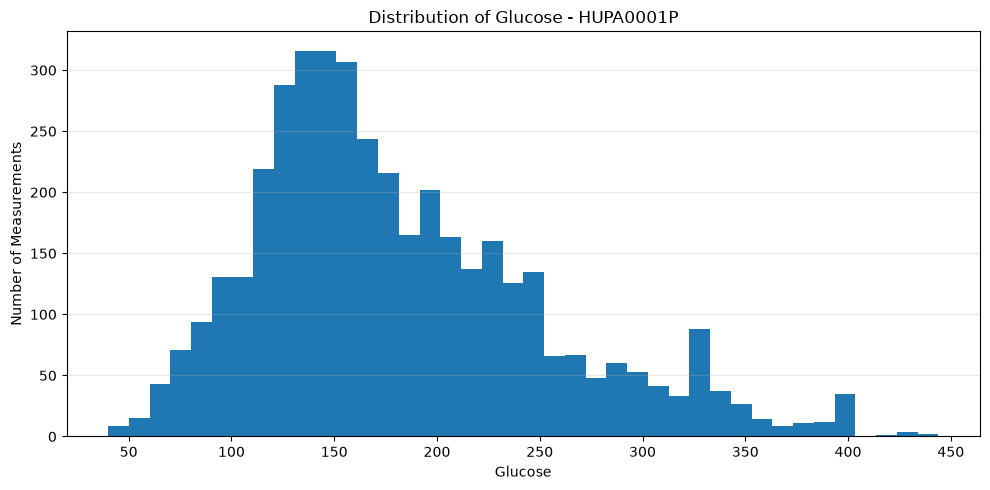

In [16]:

plt.figure(figsize=(10, 5))

plt.hist(df["glucose"].dropna(), bins=40)

plt.title("Distribution of Glucose - HUPA0001P")
plt.xlabel("Glucose")
plt.ylabel("Number of Measurements")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.show()


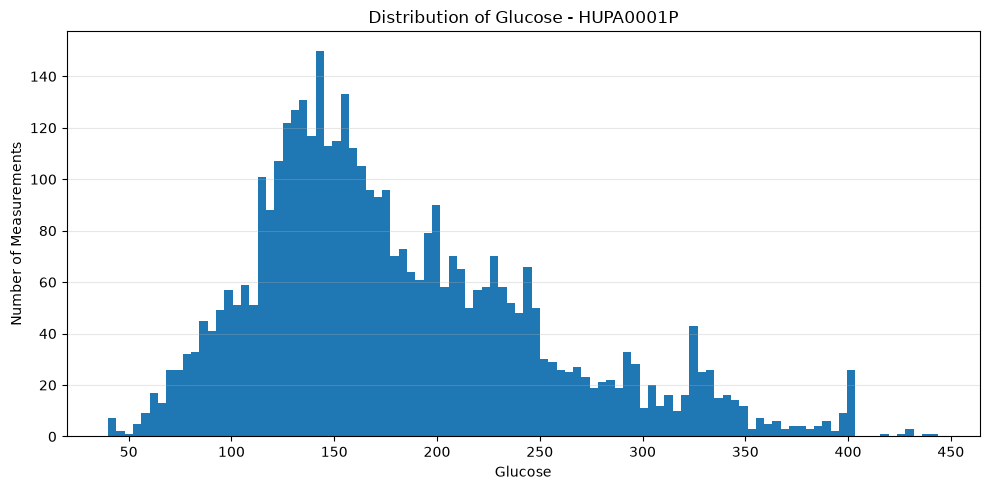

In [17]:
plt.figure(figsize=(10, 5))

plt.hist(df["glucose"].dropna(), bins=100)

plt.title("Distribution of Glucose - HUPA0001P")
plt.xlabel("Glucose")
plt.ylabel("Number of Measurements")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.show()

In [18]:

glucose = df["glucose"].dropna()

print("Glucose statistics:")
print("Mean:", glucose.mean())
print("Median:", glucose.median())
print("Standard deviation:", glucose.std())
print("Minimum:", glucose.min())
print("Maximum:", glucose.max())

print("\nPercentage of measurements in selected ranges:")

ranges = {
    "Below 70": glucose < 70,
    "70 to below 180": (glucose >= 70) & (glucose < 180),
    "180 to below 250": (glucose >= 180) & (glucose < 250),
    "250 and above": glucose >= 250
}

for name, condition in ranges.items():
    percentage = condition.mean() * 100
    print(f"{name}: {percentage:.2f}%")


Glucose statistics:
Mean: 181.4437255859375
Median: 165.66666666666666
Standard deviation: 70.64463325126245
Minimum: 40.0
Maximum: 444.0

Percentage of measurements in selected ranges:
Below 70: 1.44%
70 to below 180: 56.15%
180 to below 250: 26.95%
250 and above: 15.45%
